In [1]:
import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Block 1
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        #Flatten
        self.flatten = nn.Flatten()

        # Neural Network
        self.fc1 = nn.Linear(in_features=1568, out_features=128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(in_features=128, out_features=10)

    def forward(self,x):
        print(f"0. Input Image: {x.shape}")

        x= self.pool1(self.relu1(self.conv1(x)))
        print(f"1. AfterBlock 1 {x.shape}")

        x= self.pool2(self.relu2(self.conv2(x)))
        print(f"2. After Block 2: {x.shape}")

        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)

        return x

In [1]:
import torch
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

2.14.0+cu130
13.0
True


In [2]:
model = CNN()
dummy_data = torch.randn(4,1,28,28)
model(dummy_data)

0. Input Image: torch.Size([4, 1, 28, 28])
1. AfterBlock 1 torch.Size([4, 16, 14, 14])
2. After Block 2: torch.Size([4, 32, 7, 7])


tensor([[ 0.0053, -0.1199, -0.1187,  0.0998, -0.0593,  0.0662, -0.0082,  0.1524,
         -0.0950, -0.1651],
        [ 0.0045, -0.2548, -0.1077,  0.0626, -0.0754,  0.0677, -0.0156,  0.2114,
         -0.0464, -0.1588],
        [-0.0300, -0.2163, -0.0640,  0.0676, -0.0044,  0.0992, -0.0228,  0.1489,
         -0.0154, -0.1504],
        [ 0.0257, -0.1616, -0.0604,  0.0651, -0.0349,  0.0766, -0.0545,  0.1678,
         -0.0974, -0.1724]], grad_fn=<AddmmBackward0>)

Edge Detector Filter (Sobell)

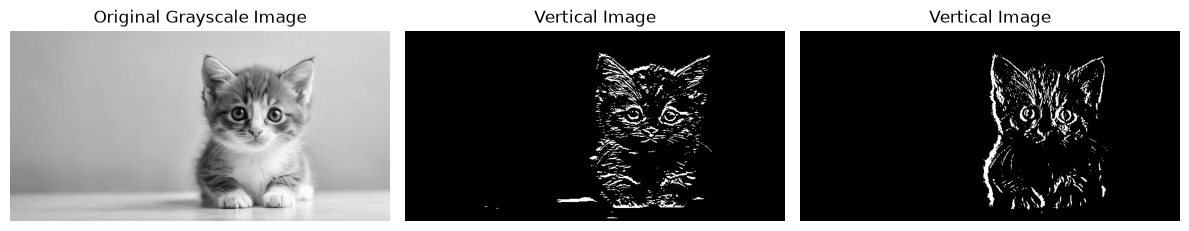

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Loading Image
image = cv2.imread('cat.jpg')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

horizontal_kernel = np.array([
    [+1,+2,+1],
    [0,0,0],
    [-1,-2,-1]
])

vertical_kernel = np.array([
    [+1,0,-1],
    [+2,0,-2],
    [+1,0,-1]
])

vertical_edge = cv2.filter2D(gray, -1, vertical_kernel)
_, binary_v_output = cv2.threshold(vertical_edge, 50, 255, cv2.THRESH_BINARY)

horz_edge = cv2.filter2D(gray, -1, horizontal_kernel)
_, binary_h_output = cv2.threshold(horz_edge, 50, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.title("Original Grayscale Image")
plt.imshow(gray, cmap='gray')
plt.axis('off')

plt.subplot(1,3,2)
plt.title("Vertical Image")
plt.imshow(binary_h_output,cmap='gray')
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Vertical Image")
plt.imshow(binary_v_output,cmap='gray')
plt.axis("off")

plt.tight_layout()
plt.show()

Real Training On CIFAR-10 Dataset

In [38]:
import torch 
import torch.nn as nn
import torch.optim as optim # Updating weights -> SGD, Adam
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [39]:
# data Augmetaion
# we are making the function for data augmetation to use later once we load the dataset 
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5), # 50% image will be flipped
    transforms.RandomRotation(degrees=10),# randomly rotate between -10 and +10 degrees
    transforms.ToTensor(), # Tensor are a data sturcture for faster calc
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)) # Normalize RGB Channels
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])


train_data = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transforms
)

test_data = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transforms
)


In [40]:
# Data Loader for Mini-Batching
train_loader = DataLoader(train_data,batch_size=128)
test_loader = DataLoader(test_data,batch_size=128)

In [ ]:
# The CNN Architecture

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Block 1
        self.conv1 = nn.Conv2d(in_channels=3,out_channels=16, kernel_size=3,padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2,stride=2)

        # Block 2
        self.conv2 = nn.Conv2d(in_channels=16,out_channels=32, kernel_size=3,padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2,stride=2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(in_features=32*8*8, out_features=128)
        self.relu3 = nn.ReLU()

        # Output Layer
        self.fc2 = nn.Linear(in_features=128,out_features=10) # Out features are 10 beacause CIFAR also have 10 classes


    def forward(self,x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)

        return x

print(f"Train Dataset Size: {len(train_data)}")
print('layer weights:', list(CNN().parameters()))

NameError: name 'x' is not defined

In [23]:
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)


epochs = 10

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        predicitions = model(images)
        loss = criterion(predicitions, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        total_correct = (predicitions.argmax(dim=1) == labels).sum().item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {total_loss/len(train_loader):.4f} | Accuracy: {total_correct/len(train_loader.dataset)*100:.4f}%")



Epoch [1/10], Loss: 1.5371 | Accuracy: 0.0840%
Epoch [2/10], Loss: 1.2528 | Accuracy: 0.0840%
Epoch [3/10], Loss: 1.1317 | Accuracy: 0.0960%
Epoch [4/10], Loss: 1.0457 | Accuracy: 0.1000%
Epoch [5/10], Loss: 0.9763 | Accuracy: 0.1080%
Epoch [6/10], Loss: 0.9215 | Accuracy: 0.1140%
Epoch [7/10], Loss: 0.8776 | Accuracy: 0.1100%
Epoch [8/10], Loss: 0.8407 | Accuracy: 0.1120%
Epoch [9/10], Loss: 0.8083 | Accuracy: 0.1180%
Epoch [10/10], Loss: 0.7785 | Accuracy: 0.1100%


Code of Lenet Architecture

In [4]:
import torch 
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [20]:
# Write a funtion  to prepare the data
transform = transforms.Compose([
    transforms.Resize((32,32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5),(0.5))
])

train_data = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_data = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cuda


In [21]:
train_loader = DataLoader(train_data,batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [22]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.feature_extractor = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride= 1),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2,stride=2),
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride= 1),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride= 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=16*5*5, out_features=120),
            nn.Tanh(),
            nn.Linear(in_features=120,out_features=84),
            nn.Tanh(),
            nn.Linear(in_features=84, out_features=10)

        )

    def forward(self,x):
        x = self.feature_extractor(x)
        x = self.classifier(x)

        return x

In [16]:
model = LeNet().to(device)

criterion= nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr= 0.001)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [18]:
for epoch in range(10):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels, in train_loader:


        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss+= loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()

    print(f"Epoch {epoch+1} | Loss: {total_loss/len(train_loader):.4f} | Acc : {(correct/len(train_data))*100:.2f}%")
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

Epoch 1 | Loss: 0.2582 | Acc : 92.64%
Epoch 2 | Loss: 0.0806 | Acc : 97.47%
Epoch 3 | Loss: 0.0540 | Acc : 98.33%
Epoch 4 | Loss: 0.0439 | Acc : 98.63%
Epoch 5 | Loss: 0.0358 | Acc : 98.91%
Epoch 6 | Loss: 0.0292 | Acc : 99.05%
Epoch 7 | Loss: 0.0246 | Acc : 99.26%
Epoch 8 | Loss: 0.0214 | Acc : 99.31%
Epoch 9 | Loss: 0.0184 | Acc : 99.43%
Epoch 10 | Loss: 0.0172 | Acc : 99.45%
cuda


In [24]:
# Testing the CNN model
model.eval()

correct = 0
total = 0
test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:
        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        # Get predicted class
        predictions = outputs.argmax(1)

        # Count correct predictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = (correct / total) * 100

print(f"Test Loss: {test_loss / len(test_loader):.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.0378
Test Accuracy: 98.84%


In [25]:
print("\n --- test set prediciotions----")
model.eval()

test_imgs, test_lbls = next(iter(test_loader))

with torch.no_grad():
    raw_outputs = model(test_imgs)

    test_preds = raw_outputs.argmax(dim=1)

show_images(test_imgs, test_lbls, test_preds)


 --- test set prediciotions----


RuntimeError: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        #Layer 1
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # LAyer 2
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Flatten
        self.flatten = nn.Flatten()

        # NN
        self.fc1 = nn.Linear(in_features = 32*7*7, out_features=128)

        # Output Layer
        self.fc2 = nn.Linear(in_features=128, out_features=10)

    # Forward Pass
    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))

In [26]:
class NN(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(in_features=32*7*7, out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=64)
        self.fc3 = nn.Linear(in_features=64, out_features=10)

        self.relu1 = nn.ReLU()
        self.relu2 = nn.ReLU()

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)

        return x

In [36]:
x = torch.randn(2, 32*7*7)  # Example input tensor with batch size of 2 and flattened size of 32*7*7
model = NN().to(device)
output = model(x)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(output.shape)

RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)

In [37]:
for epoch in range(10):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in train_loader:
        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Flatten the images
        images = images.view(images.size(0), -1)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()

    print(f"Epoch {epoch+1} | Loss: {total_loss/len(train_loader):.4f} | Acc : {(correct/len(train_data))*100:.2f}%")

RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x1024 and 1568x128)